# Ejercicio 2 — Análisis de reseñas de videojuegos con LLMs

**Pipeline de dos pasos con la API de Groq**

Este notebook aplica **Prompt Engineering** para convertir texto libre
(reseñas de videojuegos) en **información estructurada**, dividiendo el problema
en dos subtareas más simples y controlables:

1. **Filtrado (LLM 1)** — descarta reseñas poco informativas (spam, texto
   repetido, sin contenido evaluable).
2. **Extracción (LLM 2)** — sobre las reseñas relevantes extrae campos
   estructurados (sentimiento, aspectos, dificultad, rendimiento, recomendación).

> **Idea clave.** Un LLM rinde mejor haciendo *una cosa a la vez*. Separar
> "decidir si vale la pena" de "extraer los datos" hace cada prompt más simple,
> más barato y más fácil de validar.

### Decisiones de diseño (resumen)

| Decisión | Elección | Motivo |
| --- | --- | --- |
| Proveedor | **Groq** (API cloud) | Tier gratuito, muy rápido, soporta *JSON mode*. |
| Modelo filtrado | `llama-3.1-8b-instant` | Tarea casi binaria → modelo pequeño, rápido, barato. |
| Modelo extracción | `llama-3.3-70b-versatile` | Tarea matizada → modelo grande, más preciso. |
| Formato salida | JSON mode + validación | Salida parseable y determinista (`temperature=0`). |
| Batching | 10 (filtro) / 5 (extracción) | Menos llamadas, controlando tokens por llamada. |
| Rate limits | Rotación de claves + `Retry-After` | Ante un 429 salta a otra clave; si todas al límite, espera lo justo. |


## 1. Configuración del entorno

Cargamos una o varias claves Groq desde un archivo `.env` (no versionado):
`GROQ_API_KEY` y, si existen, `GROQ_API_KEY_2`, `GROQ_API_KEY_3`, … Con varias,
un `PoolClaves` rota entre ellas cuando una agota su cuota. Todo el acceso al
modelo pasa por una única función `call_llm`, así que cambiar de proveedor
afectaría a un solo sitio.


In [1]:
import os
import re
import json
import time
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from groq import Groq, RateLimitError


def cargar_claves():
    """Reúne todas las claves Groq del .env: GROQ_API_KEY y, si las hay,
    GROQ_API_KEY_2, GROQ_API_KEY_3, … Tener varias permite rotar cuando una
    agota su cuota (fallback ante rate limit)."""
    claves = [os.getenv("GROQ_API_KEY")]
    i = 2
    while os.getenv(f"GROQ_API_KEY_{i}"):
        claves.append(os.getenv(f"GROQ_API_KEY_{i}"))
        i += 1
    claves = [c for c in claves if c]
    return list(dict.fromkeys(claves))  # sin duplicados, conservando el orden


class PoolClaves:
    """Varias claves Groq con rotación automática ante rate limit.

    Cada clave tiene su propia cuota. Cuando una recibe un 429, la dejamos en
    reposo hasta su hora de recuperación y saltamos al instante a otra clave
    libre. Solo esperamos si TODAS están en reposo, y lo justo hasta que la
    primera se libere. Con una sola clave se comporta como siempre."""

    def __init__(self, claves):
        self.clientes = [Groq(api_key=c, max_retries=0) for c in claves]
        self.libre_en = [0.0] * len(self.clientes)  # ts en que cada clave se libera
        self.i = 0

    @property
    def cliente(self):
        return self.clientes[self.i]

    def rotar_tras_429(self, segundos):
        """Deja la clave actual en reposo `segundos` y salta a otra libre.
        Devuelve los segundos a esperar (0 si hay otra clave lista)."""
        self.libre_en[self.i] = time.time() + segundos
        ahora = time.time()
        n = len(self.clientes)
        for paso in range(1, n + 1):          # ¿hay alguna clave ya libre?
            j = (self.i + paso) % n
            if self.libre_en[j] <= ahora:
                self.i = j
                return 0.0
        self.i = min(range(n), key=lambda j: self.libre_en[j])  # la que antes se libera
        return max(0.0, self.libre_en[self.i] - ahora)


# Cargar las claves del .env (ver .env.example) y montar el pool
load_dotenv()
CLAVES = cargar_claves()
assert CLAVES, "Falta GROQ_API_KEY. Copia .env.example a .env y pon tu(s) clave(s)."
pool = PoolClaves(CLAVES)

# Dos modelos distintos: uno por tarea (separación de responsabilidades)
MODELO_FILTRO = "llama-3.1-8b-instant"        # Paso 2: filtrado (barato/rápido)
MODELO_EXTRACCION = "llama-3.3-70b-versatile"  # Paso 3: extracción (más capaz)
plural = "s" if len(CLAVES) > 1 else ""
print(f"Cliente Groq listo ({len(CLAVES)} clave{plural} en el pool).")

Cliente Groq listo (2 claves en el pool).


### Parámetros del pipeline

Centralizamos aquí los parámetros que gobiernan **coste y límites**. Están
justificados más abajo, en cada paso.

- `N_RESENAS`: cuántas reseñas procesar. Para **probar sin gastar cuota**, baja
  este número (p. ej. 10); para la entrega final, 100.
- `TAM_BATCH_*`: reseñas por llamada. Menos llamadas = menos riesgo de rate
  limit, pero más tokens por llamada. Se elige menor en extracción (respuestas
  más largas).
- `MAX_CHARS_*`: recorte del texto enviado. Las reseñas más largas superan los
  7.000 caracteres; recortarlas controla los tokens de entrada sin perder la
  parte informativa (que suele estar al principio).
- `PAUSA_*`: espera entre llamadas. El tier gratuito limita **tokens por minuto**
  (TPM), y el modelo 70B de extracción consume muchos más por llamada, así que
  pausa más que el filtrado para no saturar la ventana de TPM.


In [2]:
N_RESENAS = 100            # nº de reseñas a procesar (baja a ~10 para pruebas)

TAM_BATCH_FILTRO = 10      # reseñas por llamada en el filtrado
TAM_BATCH_EXTRACCION = 5   # reseñas por llamada en la extracción (respuestas más largas)

MAX_CHARS_FILTRO = 1200    # recorte de texto para decidir relevancia
MAX_CHARS_EXTRACCION = 2000  # recorte de texto para extraer datos (controla tokens/min)

# El tier gratuito limita tokens/minuto (TPM). La extracción usa el modelo 70B
# (muchos más tokens por llamada), por eso pausa más que el filtrado.
PAUSA_FILTRO = 2.0
PAUSA_EXTRACCION = 6.0

### Función única de acceso al LLM

`call_llm` centraliza el acceso al modelo y, sobre todo, la **gestión del rate
limit** (el punto crítico del tier gratuito):

- **`temperature=0`** → salida determinista y reproducible (queremos extraer
  datos, no ser creativos).
- **JSON mode** (`response_format={"type": "json_object"}`) → Groq garantiza un
  JSON válido, lo que reduce errores de parseo. Requiere un objeto JSON de nivel
  superior, por eso nuestros esquemas envuelven la lista en `{"resultados": [...]}`.
- **Manejo de 429 con rotación de claves** → cuando una clave supera su límite,
  Groq responde `429`. En vez de quedarnos esperando, saltamos a otra clave del
  pool y reintentamos al instante. Si todas están al límite, esperamos lo justo
  —lo que indica la cabecera `Retry-After`— hasta que la primera se libere. Así
  el pipeline avanza sin frenar por rate limit.
- **Backoff exponencial** para el resto de errores transitorios (red, 5xx).


In [3]:
def _espera_rate_limit(e, intento, base):
    """Segundos que debe reposar una clave tras un 429.

    Prioridad: (1) cabecera Retry-After que envía Groq, (2) el tiempo del mensaje
    de error ("try again in 7.5s"), (3) backoff exponencial acotado.
    """
    espera = None
    resp = getattr(e, "response", None)
    if resp is not None:
        cabecera = (resp.headers.get("retry-after")
                    or resp.headers.get("x-ratelimit-reset-tokens"))
        if cabecera:
            m = re.search(r"[\d.]+", str(cabecera))
            if m:
                espera = float(m.group())
    if espera is None:
        m = re.search(r"in ([\d.]+)s", str(e))
        if m:
            espera = float(m.group(1))
    if espera is None:
        espera = min(base * (2 ** (intento - 1)), 60.0)  # sin dato de Groq: backoff acotado
    return espera + 1.0  # pequeño margen de seguridad


def _fmt_espera(seg):
    """Espera legible: '45 s' o '1 min 12 s'."""
    seg = int(round(seg))
    if seg < 60:
        return f"{seg} s"
    return f"{seg // 60} min {seg % 60:02d} s"


def call_llm(system, user, model, max_tokens=1024, temperature=0.0,
             json_mode=True, max_reintentos=8, pausa_base=2.0):
    """Llama a Groq (rotando de clave ante rate limit) y devuelve el texto.

    - Ante un 429 salta a otra clave del pool y reintenta al instante; si todas
      están al límite, espera lo justo hasta que una se libere.
    - Otros errores transitorios (red, 5xx) -> backoff exponencial.
    - temperature=0 y JSON mode -> salida determinista y parseable.
    """
    kwargs = dict(
        model=model,
        temperature=temperature,
        max_tokens=max_tokens,
        messages=[
            {"role": "system", "content": system},
            {"role": "user", "content": user},
        ],
    )
    if json_mode:
        kwargs["response_format"] = {"type": "json_object"}

    for intento in range(1, max_reintentos + 1):
        try:
            resp = pool.cliente.chat.completions.create(**kwargs)
            return resp.choices[0].message.content
        except RateLimitError as e:
            if intento == max_reintentos:
                raise
            espera = pool.rotar_tras_429(_espera_rate_limit(e, intento, pausa_base))
            if espera:
                print(f"  Claves al límite, sigo en {_fmt_espera(espera)}.")
                time.sleep(espera)
            else:
                print("  Clave saturada, cambio a otra.")
        except Exception as e:  # noqa: BLE001 (errores transitorios de red/servidor)
            if intento == max_reintentos:
                raise
            espera = pausa_base * intento
            print(f"  Error de red ({type(e).__name__}), reintento en {_fmt_espera(espera)}.")
            time.sleep(espera)


def parse_json_seguro(texto):
    """Parsea JSON de forma defensiva: si viene con texto alrededor, recorta a las llaves."""
    try:
        return json.loads(texto)
    except json.JSONDecodeError:
        ini, fin = texto.find("{"), texto.rfind("}")
        if ini != -1 and fin != -1:
            return json.loads(texto[ini:fin + 1])
        raise

## 2. Carga y exploración de los datos

El dataset tiene 20.000 reseñas con tres columnas: `Contenido` (texto libre),
`Valoración` (*Recomendado* / *No recomendado*) y `Recomendado_binario` (1/0).


In [4]:
DATA_PATH = Path("data/videogames_reviews.csv")
df = pd.read_csv(DATA_PATH, index_col=0)

print("Dimensiones:", df.shape)
print("Columnas:", list(df.columns))
df.head(3)

Dimensiones: (20000, 3)
Columnas: ['Contenido', 'Valoración', 'Recomendado_binario']


,Contenido,Valoración,Recomendado_binario
0,2 marzo so bad,No recomendado,0
1,10 febrero actualmente recomiendo juego contab...,No recomendado,0
2,9 febrero increíblemente gracioso ver cómo cdp...,No recomendado,0


In [5]:
print("Nulos por columna:")
print(df.isna().sum(), "\n")

print("Distribución de Valoración:")
print(df["Valoración"].value_counts(), "\n")

longitudes = df["Contenido"].dropna().str.len()
print("Longitud de Contenido (nº de caracteres):")
print(longitudes.describe().round(1))

Nulos por columna:
Contenido              288
Valoración               0
Recomendado_binario      0
dtype: int64 

Distribución de Valoración:
Valoración
No recomendado    10000
Recomendado       10000
Name: count, dtype: int64 

Longitud de Contenido (nº de caracteres):
count    19712.0
mean       295.8
std        734.8
min          1.0
25%         25.0
50%         74.0
75%        233.0
max       7972.0
Name: Contenido, dtype: float64


**Observaciones**

- Hay `288` reseñas con `Contenido` nulo → habrá que descartarlas.
- El dataset está **balanceado**: 50% Recomendado / 50% No recomendado.
- Enorme dispersión de longitud: de `1` a casi `8.000` caracteres. Muchas reseñas
  cortísimas ("l", "f", "c") son puro ruido; las largas concentran la información.


## 3. Paso 1 — Selección de las 100 reseñas más largas

El enunciado parte de las **100 reseñas con mayor longitud** (las más
informativas). Implementamos esa selección y, de paso, limpiamos:

- eliminamos `Contenido` nulo o vacío,
- quitamos **duplicados exactos** (reseñas copiadas/repetidas),
- ordenamos por longitud y tomamos las `N_RESENAS` primeras.

El índice original del CSV se conserva como columna **`Id`**, que usaremos para
seguir cada reseña a lo largo de todo el pipeline.


In [6]:
def seleccionar_top_largas(df, n=100):
    """Devuelve las n reseñas más largas, sin nulos, vacíos ni duplicados."""
    limpio = df.dropna(subset=["Contenido"]).copy()
    limpio["Contenido"] = limpio["Contenido"].str.strip()
    limpio = limpio[limpio["Contenido"] != ""]
    limpio = limpio.drop_duplicates(subset=["Contenido"])
    limpio["longitud"] = limpio["Contenido"].str.len()
    return limpio.sort_values("longitud", ascending=False).head(n)


df_top = seleccionar_top_largas(df, n=N_RESENAS).reset_index(names="Id")

print(f"Reseñas seleccionadas: {len(df_top)}")
print(f"Rango de longitud: {df_top['longitud'].min()} - {df_top['longitud'].max()} caracteres")
print("Valoración en la muestra:", df_top["Valoración"].value_counts().to_dict())
df_top[["Id", "Valoración", "longitud"]].head()

Reseñas seleccionadas: 100
Rango de longitud: 5121 - 7972 caracteres
Valoración en la muestra: {'No recomendado': 63, 'Recomendado': 37}


,Id,Valoración,longitud
0,19502,Recomendado,7972
1,17660,Recomendado,7662
2,4187,No recomendado,7638
3,5415,No recomendado,7609
4,7751,No recomendado,7609


## 4. Paso 2 — Filtrado de relevancia (LLM 1)

Aunque ya seleccionamos las reseñas más largas, "largo" no implica "útil": puede
haber texto repetido, listas sin sentido o divagaciones sin opinión evaluable.
Pedimos al **primer LLM** que marque cada reseña como **relevante** o
**irrelevante**.

### Diseño del prompt

- **Rol claro**: "analista de reseñas de videojuegos".
- **Criterios explícitos** de qué es relevante y qué no (reduce ambigüedad).
- **Esquema de salida cerrado**: `{"resultados": [{"id", "relevante", "motivo"}]}`.
  Envolvemos la lista en un objeto porque el *JSON mode* de Groq exige un objeto
  de nivel superior.
- **`id` explícito** en cada objeto → no dependemos del orden para casar
  resultados con reseñas.

### Batching y límites

- **10 reseñas por llamada**: reduce el nº de llamadas de 100 a 10. Como para
  juzgar relevancia basta el inicio del texto, **recortamos a
  `MAX_CHARS_FILTRO` caracteres** y así controlamos los tokens de entrada.
- **`time.sleep(PAUSA_FILTRO)`** entre llamadas para no superar el rate limit del
  tier gratuito (y, si aun así llega un 429, `call_llm` espera lo que pida Groq).


In [7]:
SYSTEM_FILTRO = """Eres un analista de reseñas de videojuegos. Clasificas cada reseña como RELEVANTE o IRRELEVANTE para un análisis de opiniones.

RELEVANTE: aporta información evaluable (opiniones, aspectos positivos/negativos, jugabilidad, historia, rendimiento, precio, comparaciones, etc.).

IRRELEVANTE: no permite extraer opiniones útiles (texto vacío o de relleno, caracteres o palabras repetidas sin sentido, spam, sólo emojis, texto ininteligible o sin contenido semántico sobre el juego).

Responde ÚNICAMENTE con un JSON válido con esta forma EXACTA:
{"resultados": [{"id": <entero>, "relevante": true|false, "motivo": "<breve>"}]}
Incluye un objeto por cada reseña recibida."""


def construir_prompt_filtro(batch):
    """Arma el mensaje de usuario con las reseñas del lote (texto recortado)."""
    lineas = []
    for _, fila in batch.iterrows():
        texto = fila["Contenido"][:MAX_CHARS_FILTRO]
        lineas.append(f'ID {fila["Id"]}: "{texto}"')
    reseñas = "\n\n".join(lineas)
    return (
        f"Clasifica estas {len(batch)} reseñas y devuelve el JSON pedido "
        f"(un objeto por reseña):\n\n{reseñas}"
    )

In [8]:
def filtrar_reseñas(df_top, tam_batch, pausa):
    """Recorre la muestra por lotes y devuelve (ids_relevantes, df_decisiones)."""
    decisiones = []
    n_lotes = (len(df_top) + tam_batch - 1) // tam_batch
    for i in range(0, len(df_top), tam_batch):
        batch = df_top.iloc[i:i + tam_batch]
        user = construir_prompt_filtro(batch)
        raw = call_llm(SYSTEM_FILTRO, user, MODELO_FILTRO,
                       max_tokens=1500, pausa_base=pausa)
        data = parse_json_seguro(raw)
        decisiones.extend(data.get("resultados", []))
        print(f"Lote {i // tam_batch + 1}/{n_lotes}: {len(batch)} reseñas procesadas")
        time.sleep(pausa)

    df_decisiones = pd.DataFrame(decisiones)
    ids_relevantes = [int(r["id"]) for r in decisiones if r.get("relevante")]
    return ids_relevantes, df_decisiones


ids_relevantes, df_decisiones = filtrar_reseñas(df_top, TAM_BATCH_FILTRO, PAUSA_FILTRO)

df_filtrado = df_top[df_top["Id"].isin(ids_relevantes)].copy()
n_desc = len(df_top) - len(df_filtrado)
print(f"\nRelevantes: {len(df_filtrado)} / {len(df_top)}  (descartadas: {n_desc})")

Lote 1/10: 10 reseñas procesadas
  Clave saturada, cambio a otra.
Lote 2/10: 10 reseñas procesadas
  Claves al límite, sigo en 13 s.
Lote 3/10: 10 reseñas procesadas
  Claves al límite, sigo en 12 s.
Lote 4/10: 10 reseñas procesadas
  Claves al límite, sigo en 16 s.
Lote 5/10: 10 reseñas procesadas
  Claves al límite, sigo en 12 s.
  Claves al límite, sigo en 10 s.
Lote 6/10: 10 reseñas procesadas
  Claves al límite, sigo en 13 s.
Lote 7/10: 10 reseñas procesadas
  Claves al límite, sigo en 3 s.
Lote 8/10: 10 reseñas procesadas
  Claves al límite, sigo en 24 s.
Lote 9/10: 10 reseñas procesadas
  Claves al límite, sigo en 13 s.
Lote 10/10: 10 reseñas procesadas

Relevantes: 90 / 100  (descartadas: 10)


In [9]:
# Ejemplos de reseñas DESCARTADAS y el motivo dado por el modelo
irrelevantes = df_decisiones[~df_decisiones["relevante"]]
if len(irrelevantes):
    display(irrelevantes[["id", "motivo"]].head(10))
else:
    print("El modelo no descartó ninguna reseña de la muestra (todas informativas).")

,id,motivo
0,19502,Texto vacío o de relleno sin sentido
27,19075,No proporciona información evaluable sobre el ...
28,14650,"No se refiere a Cyberpunk 2077, sino a The Eld..."
50,450,Texto vacío o de relleno.
57,1197,Es un texto vacío y no proporciona ninguna inf...
60,3982,Es un texto vacío y no proporciona ninguna inf...
67,17487,Reseña muy corta y sin contenido semántico
78,14895,Texto ininteligible y sin contenido semántico ...
82,1233,"Texto incompleto y difícil de entender, con er..."
88,2983,"Texto incompleto y difícil de entender, con er..."


## 5. Paso 3 — Extracción de información estructurada (LLM 2)

Sobre las reseñas ya filtradas, un **segundo modelo más capaz**
(`llama-3.3-70b-versatile`) extrae un JSON por reseña con estos campos
(**7 entidades**, por encima del mínimo de 3):

| Campo | Valores |
| --- | --- |
| `SentimientoGeneral` | Positivo · Negativo · Neutral |
| `AspectosPositivos` | lista de textos breves |
| `AspectosNegativos` | lista de textos breves |
| `Dificultad` | Demasiado Fácil · Fácil · Equilibrado · Difícil · Demasiado Difícil · No Mencionado |
| `Rendimiento` | Bueno · Aceptable · Problemático · No Mencionado |
| `RecomendadoLLM` | Recomendado · No recomendado |

Añadimos **`Rendimiento`** (bugs/optimización, muy citado en videojuegos) y
**`RecomendadoLLM`** (recomendación inferida por el modelo), que luego
contrastamos con la `Valoración` real como comprobación de coherencia.

### Por qué lotes más pequeños (y más pausa)

Este paso usa el modelo **70B**, mucho más costoso en tokens. El tier gratuito
limita los **tokens por minuto (TPM)**, así que:

- **5 reseñas por llamada** (frente a 10 en el filtrado): respuestas más largas
  (listas de aspectos); un lote grande podría **agotar `max_tokens` de salida** y
  truncar el JSON.
- **más pausa** entre llamadas (`PAUSA_EXTRACCION`) para no saturar la ventana de
  TPM, y `MAX_CHARS_EXTRACCION` recortado para bajar los tokens de entrada.
- si aun así se supera el límite, `call_llm` captura el **429** y **salta a otra
  clave** del pool; solo espera (lo que indique **`Retry-After`**) si todas están
  al límite.


In [10]:
SYSTEM_EXTRACCION = """Eres un analista experto en reseñas de videojuegos. Extrae información estructurada de cada reseña.

Devuelve ÚNICAMENTE un JSON válido con esta forma EXACTA:
{"resultados": [
  {
    "id": <entero>,
    "SentimientoGeneral": "Positivo" | "Negativo" | "Neutral",
    "AspectosPositivos": ["<aspecto breve>", ...],
    "AspectosNegativos": ["<aspecto breve>", ...],
    "Dificultad": "Demasiado Fácil" | "Fácil" | "Equilibrado" | "Difícil" | "Demasiado Difícil" | "No Mencionado",
    "Rendimiento": "Bueno" | "Aceptable" | "Problemático" | "No Mencionado",
    "RecomendadoLLM": "Recomendado" | "No recomendado"
  }
]}

Reglas:
- Usa EXACTAMENTE los valores permitidos en los campos categóricos.
- Si un aspecto no se menciona, usa lista vacía [] o "No Mencionado".
- Devuelve un objeto por cada reseña recibida."""


def construir_prompt_extraccion(batch):
    lineas = []
    for _, fila in batch.iterrows():
        texto = fila["Contenido"][:MAX_CHARS_EXTRACCION]
        lineas.append(f'ID {fila["Id"]}: "{texto}"')
    reseñas = "\n\n".join(lineas)
    return (
        f"Extrae la información de estas {len(batch)} reseñas y devuelve el JSON "
        f"pedido (un objeto por reseña):\n\n{reseñas}"
    )

In [11]:
def extraer_estructura(df_filtrado, tam_batch, pausa):
    """Recorre las reseñas relevantes por lotes y devuelve la lista de registros."""
    registros = []
    n_lotes = (len(df_filtrado) + tam_batch - 1) // tam_batch
    for i in range(0, len(df_filtrado), tam_batch):
        batch = df_filtrado.iloc[i:i + tam_batch]
        user = construir_prompt_extraccion(batch)
        raw = call_llm(SYSTEM_EXTRACCION, user, MODELO_EXTRACCION,
                       max_tokens=2000, pausa_base=pausa)
        data = parse_json_seguro(raw)
        registros.extend(data.get("resultados", []))
        print(f"Lote {i // tam_batch + 1}/{n_lotes}: {len(batch)} reseñas extraídas")
        time.sleep(pausa)
    return registros


registros = extraer_estructura(df_filtrado, TAM_BATCH_EXTRACCION, PAUSA_EXTRACCION)
print(f"\nReseñas con información extraída: {len(registros)}")

Lote 1/18: 5 reseñas extraídas
Lote 2/18: 5 reseñas extraídas
Lote 3/18: 5 reseñas extraídas
  Claves al límite, sigo en 4 s.
Lote 4/18: 5 reseñas extraídas
  Clave saturada, cambio a otra.
  Claves al límite, sigo en 9 s.
Lote 5/18: 5 reseñas extraídas
  Claves al límite, sigo en 7 s.
Lote 6/18: 5 reseñas extraídas
  Claves al límite, sigo en 7 s.
Lote 7/18: 5 reseñas extraídas
  Claves al límite, sigo en 7 s.
Lote 8/18: 5 reseñas extraídas
  Claves al límite, sigo en 7 s.
Lote 9/18: 5 reseñas extraídas
  Claves al límite, sigo en 7 s.
Lote 10/18: 5 reseñas extraídas
  Claves al límite, sigo en 7 s.
Lote 11/18: 5 reseñas extraídas
  Claves al límite, sigo en 7 s.
Lote 12/18: 5 reseñas extraídas
  Claves al límite, sigo en 6 s.
Lote 13/18: 5 reseñas extraídas
  Claves al límite, sigo en 7 s.
Lote 14/18: 5 reseñas extraídas
  Claves al límite, sigo en 8 s.
Lote 15/18: 5 reseñas extraídas
  Claves al límite, sigo en 7 s.
Lote 16/18: 5 reseñas extraídas
  Claves al límite, sigo en 8 s.
Lo

### Construcción del DataFrame final

Unimos la salida del LLM con los metadatos originales (`Valoración`,
`Recomendado_binario`) usando el `Id`, y ordenamos las columnas.


In [12]:
df_extraido = pd.DataFrame(registros).rename(columns={"id": "Id"})

# Convertir listas a texto legible para el CSV
for col in ["AspectosPositivos", "AspectosNegativos"]:
    df_extraido[col] = df_extraido[col].apply(
        lambda xs: "; ".join(xs) if isinstance(xs, list) else (xs or "")
    )

# Unir con metadatos originales
df_final = df_extraido.merge(
    df_top[["Id", "Valoración", "Recomendado_binario"]],
    on="Id", how="left",
)

columnas = [
    "Id", "SentimientoGeneral", "AspectosPositivos", "AspectosNegativos",
    "Dificultad", "Rendimiento", "RecomendadoLLM",
    "Valoración", "Recomendado_binario",
]
df_final = df_final[columnas]
print("Forma del resultado:", df_final.shape)
df_final.head()

Forma del resultado: (90, 9)


,Id,SentimientoGeneral,AspectosPositivos,AspectosNegativos,Dificultad,Rendimiento,RecomendadoLLM,Valoración,Recomendado_binario
0,17660,Positivo,entorno urbano detallado; verticalidad en Nigh...,,No Mencionado,Bueno,Recomendado,Recomendado,1
1,4187,Negativo,experiencia previa con CDPR; alta expectativa,desilusión con el estado actual del juego; com...,No Mencionado,Problemático,No recomendado,No recomendado,0
2,5415,Negativo,entorno y historia fascinantes,diseño punitivo; enemigos difíciles de leer; p...,Difícil,Problemático,No recomendado,No recomendado,0
3,7751,Negativo,combate y animaciones; historia y mundo,decisiones de diseño no pensadas; falta de inn...,Difícil,No Mencionado,No recomendado,No recomendado,0
4,16503,Neutral,interés en la historia y personajes; mundo cre...,sistema de lifepaths decepcionante; no cumple ...,No Mencionado,No Mencionado,No recomendado,Recomendado,1


## 6. Exportación del resultado

Guardamos el DataFrame estructurado en `output/analisis_videojuegos_resultados.csv`
con codificación `utf-8-sig` (para que Excel muestre bien los acentos).


In [13]:
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)
OUT_PATH = OUT_DIR / "analisis_videojuegos_resultados.csv"
df_final.to_csv(OUT_PATH, index=False, encoding="utf-8-sig")
print("Guardado en:", OUT_PATH.resolve())

Guardado en: C:\Users\jcast\OneDrive - ebal information technology\Escritorio\Pontia\output\analisis_videojuegos_resultados.csv


## 7. Análisis de los resultados (insights)

Con la información ya estructurada podemos obtener conclusiones rápidas que sobre
el texto crudo serían imposibles: distribución de sentimiento y dificultad, y una
**comprobación de coherencia** entre la recomendación inferida por el LLM y la
`Valoración` real (un *sanity check* de extremo a extremo del pipeline).


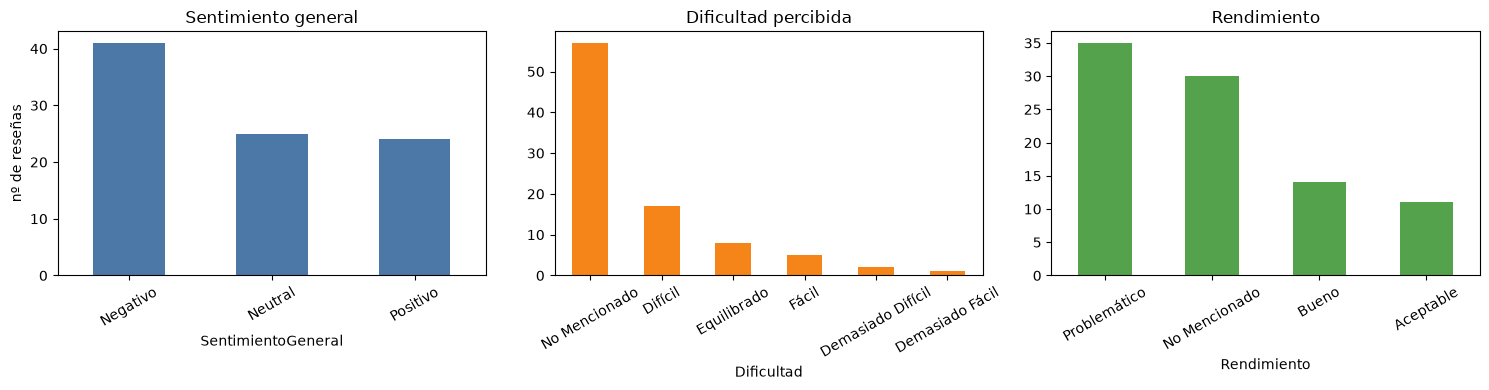

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df_final["SentimientoGeneral"].value_counts().plot(
    kind="bar", ax=axes[0], color="#4C78A8", title="Sentimiento general")
axes[0].set_ylabel("nº de reseñas")

df_final["Dificultad"].value_counts().plot(
    kind="bar", ax=axes[1], color="#F58518", title="Dificultad percibida")

df_final["Rendimiento"].value_counts().plot(
    kind="bar", ax=axes[2], color="#54A24B", title="Rendimiento")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [15]:
# Sanity check: coherencia entre la recomendación inferida y la valoración real
coherencia = (df_final["RecomendadoLLM"] == df_final["Valoración"]).mean()
print(f"Coherencia LLM vs Valoración real: {coherencia:.1%}")

print("\nTabla cruzada (LLM x real):")
pd.crosstab(df_final["RecomendadoLLM"], df_final["Valoración"])

Coherencia LLM vs Valoración real: 86.7%

Tabla cruzada (LLM x real):


Valoración,No recomendado,Recomendado
RecomendadoLLM,,
No recomendado,54,7
Recomendado,5,24


## 8. Conclusiones y justificación de decisiones

**Enfoque en dos pasos.** Separar *filtrar* de *extraer* simplifica cada prompt,
reduce el coste (el filtrado usa un modelo pequeño) y facilita depurar cada
etapa por separado.

**Proveedor y modelos.** Groq ofrece un tier gratuito rápido con *JSON mode*. Se
usan **dos modelos**: `llama-3.1-8b-instant` para la decisión casi binaria del
filtrado y `llama-3.3-70b-versatile` para la extracción, que requiere más
comprensión.

**Gestión de límites (lo que valora el enunciado):**

- **Tokens por llamada** — recortamos el texto (`MAX_CHARS_*`) porque las reseñas
  llegan a ~8.000 caracteres; la parte informativa suele estar al principio.
- **Tamaño de lote** — 10 en filtrado (respuesta corta) y 5 en extracción
  (respuesta larga, para no truncar el JSON con `max_tokens`).
- **Nº de llamadas** — con lotes pasamos de ~100 llamadas por paso a ~10 (filtro)
  y ~20 (extracción), reduciendo la exposición a rate limits.
- **Rate limits** — pausas entre llamadas y, sobre todo, manejo del **429 con
  rotación de claves**: si una clave agota su cuota, saltamos a otra del pool y
  reintentamos al instante; solo esperamos (lo que indique `Retry-After`) si
  todas están al límite. El resto de errores transitorios usan backoff
  exponencial.
- **`temperature=0` + JSON mode** — salida determinista y parseable, con parseo
  defensivo por si acaso.

**Resultado.** Un CSV estructurado (`output/analisis_videojuegos_resultados.csv`)
listo para análisis, con una coherencia alta frente a la valoración real que
confirma que la extracción capta bien el sentido de cada reseña.
